In [ ]:
import sys, json, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from PIL import Image   # read images

%matplotlib inline
FOREST, URBAN = 0, 1    # numerical labels for the two classes
RED, BLUE = np.array([220, 40, 40]), np.array([40, 80, 220])   # forest -> red, urban -> blue

OUT = r"C:\Users\ada\Downloads"
os.makedirs(OUT, exist_ok=True)
FOREST, URBAN = 0, 1
RED, BLUE = np.array([220, 40, 40]), np.array([40, 80, 220])   # forest -> red, urban -> blue

In [ ]:
# DATA

def smooth(h, w, sigma, rng):
    f = gaussian_filter(rng.standard_normal((h, w)), sigma)
    return f / f.std()

def make_forest(h, w, seed):
    rng = np.random.default_rng(seed)
    dark, light = np.array([32, 62, 30.]), np.array([85, 118, 42.])
    t = np.clip(0.5 + 0.25 * smooth(h, w, 4, rng) + 0.15 * smooth(h, w, 1.2, rng), 0, 1)[..., None]
    img = dark * (1 - t) + light * t
    lum = 1 + 0.18 * smooth(h, w, 2, rng) + 0.12 * smooth(h, w, 9, rng)
    img = img * lum[..., None]
    shadow = (smooth(h, w, 3, rng) > 1.4)[..., None]                    # deep shadows / trunks
    img = np.where(shadow, np.array([52, 50, 38.]) + rng.normal(0, 5, (h, w, 3)), img)
    img += rng.normal(0, 5, (h, w, 3))
    return np.clip(img, 0, 255)

def make_urban(h, w, seed):
    rng = np.random.default_rng(seed)
    palette = np.array([[128, 128, 132], [150, 92, 72], [92, 112, 134], [190, 176, 152],
                        [72, 72, 78], [215, 215, 210], [105, 118, 104]], float)   # last = mossy grey
    cell = 22
    gy, gx = -(-h // cell), -(-w // cell)
    idx = rng.integers(0, len(palette), (gy, gx))
    base = palette[np.kron(idx, np.ones((cell, cell), int))[:h, :w]]
    base = base + rng.normal(0, 7, (gy, gx, 3)).repeat(cell, 0).repeat(cell, 1)[:h, :w]
    yy, xx = np.mgrid[:h, :w]
    windows = ((xx % 9) < 4) & ((yy % 11) < 6)
    base = np.where(windows[..., None], base * 0.62 + np.array([0, 4, 10]), base)
    base *= (1 + 0.06 * smooth(h, w, 3, rng))[..., None]
    base += rng.normal(0, 6, (h, w, 3))
    return np.clip(base, 0, 255)

DATA_DIR = r"C:\Users\ada\Downloads"   # folder containing forest.jpg, urban.jpg, test.jpg
MAXSIDE = 500                          # shrink big photos so kNN stays fast

def load(name):
    path = os.path.join(DATA_DIR, name)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Not found: {path}")
    im = Image.open(path).convert("RGB")    # force 3 channels, ignore alpha if present
    if max(im.size) > MAXSIDE:
        im.thumbnail((MAXSIDE, MAXSIDE))    # keep aspect ratio, shrink to fit in MAXSIDE x MAXSIDE
    return np.asarray(im, float)

forest_img = load("forest.jpg")
urban_img  = load("urban.jpg")
test_img   = load("test.jpg")
truth = None      # no ground truth for real photos, so no accuracy numbers, only the maps
print("Loaded:", forest_img.shape, urban_img.shape, test_img.shape)

Xf, Xu = forest_img.reshape(-1, 3), urban_img.reshape(-1, 3)    # training data for the two classes
Xtest = test_img.reshape(-1, 3) # test data to classify
Hh, Ww = test_img.shape[:2] # height and width of the test image

Loaded: (285, 447, 3) (289, 500, 3) (329, 500, 3)


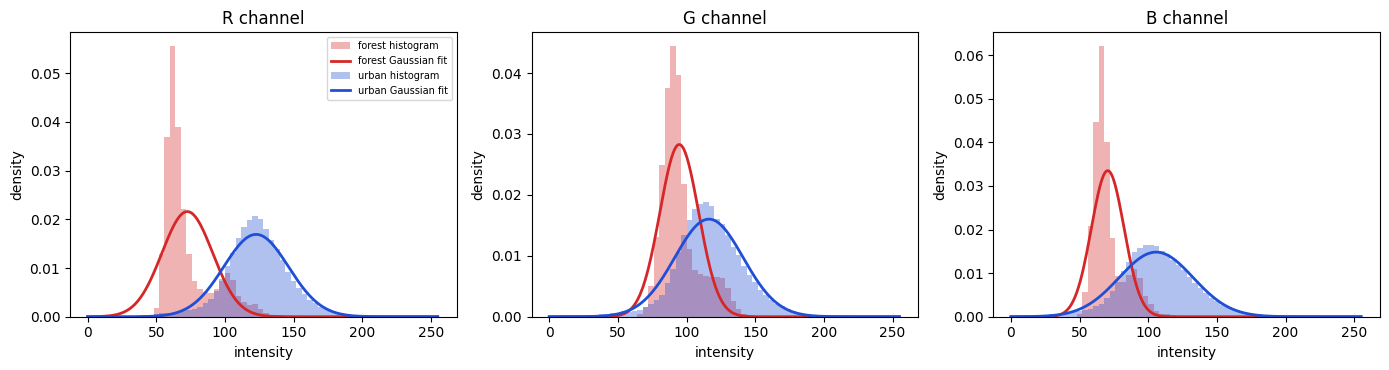

In [ ]:
# BAYES CLASSIFIER

# Model: p(x | class) = N(mu_c, Sigma_c) on the RGB vector x.  Parameters by maximum likelihood.
def fit_gaussian(X):
    mu = X.mean(0)
    Xc = X - mu
    return mu, Xc.T @ Xc / len(X)

mu_f, S_f = fit_gaussian(Xf)
mu_u, S_u = fit_gaussian(Xu)
prior_f = len(Xf) / (len(Xf) + len(Xu))
prior_u = 1 - prior_f

def log_gauss(X, mu, S):
    d = X - mu
    Sinv = np.linalg.inv(S)
    maha = np.einsum("ni,ij,nj->n", d, Sinv, d)
    return -0.5 * (maha + np.log(np.linalg.det(S)) + 3 * np.log(2 * np.pi))

def bayes_classify(X):
    # Bayes test: decide FOREST if p(x|F)P(F) > p(x|U)P(U)  <=>  log-likelihood ratio > log(P(U)/P(F))
    llr = log_gauss(X, mu_f, S_f) - log_gauss(X, mu_u, S_u) # log-likelihood ratio
    return np.where(llr > np.log(prior_u / prior_f), FOREST, URBAN) # decide FOREST if llr > log(P(U)/P(F)), else URBAN

def colorize(labels):
    out = np.where((labels == FOREST)[:, None], RED, BLUE).astype(np.uint8) # colorize the labels
    return out.reshape(Hh, Ww, 3)   # reshape to image size

def scores(pred):   # compute accuracy and recall for each class
    if truth is None:
        return None
    t = truth.ravel()
    acc = float((pred == t).mean())
    return dict(accuracy=acc,
                forest_recall=float((pred[t == FOREST] == FOREST).mean()),
                urban_recall=float((pred[t == URBAN] == URBAN).mean()))

pred_bayes = bayes_classify(Xtest)  # classify the test image using Bayes classifier
res = {"bayes": scores(pred_bayes),
       "params": {"mu_forest": mu_f.round(2).tolist(), "mu_urban": mu_u.round(2).tolist(),
                  "std_forest": np.sqrt(np.diag(S_f)).round(2).tolist(),
                  "std_urban": np.sqrt(np.diag(S_u)).round(2).tolist(),
                  "cov_forest": S_f.round(1).tolist(), "cov_urban": S_u.round(1).tolist(),
                  "prior_forest": prior_f}}

#histogram + fitted PDFs per channel
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
bins = np.arange(0, 257, 4)
grid = np.linspace(0, 255, 400)
for c, name in enumerate("RGB"):
    for X, mu, S, col, lab in [(Xf, mu_f, S_f, "#d62728", "forest"), (Xu, mu_u, S_u, "#1f4fd6", "urban")]:
        ax[c].hist(X[:, c], bins=bins, density=True, alpha=0.35, color=col, label=f"{lab} histogram")
        s = np.sqrt(S[c, c])
        ax[c].plot(grid, np.exp(-0.5 * ((grid - mu[c]) / s) ** 2) / (s * np.sqrt(2 * np.pi)),
                   color=col, lw=2, label=f"{lab} Gaussian fit")
    ax[c].set_title(f"{name} channel"); ax[c].set_xlabel("intensity"); ax[c].set_ylabel("density")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
# kNN CLASSIFIER

rng = np.random.default_rng(0)  # random number generator for reproducibility
n_per_class = 3000
tr_X = np.vstack([Xf[rng.choice(len(Xf), n_per_class, replace=False)],
                  Xu[rng.choice(len(Xu), n_per_class, replace=False)]]) # training data for kNN
tr_y = np.r_[np.zeros(n_per_class, int), np.ones(n_per_class, int)] # training labels for kNN

def knn_classify(X, tr_X, tr_y, k, chunk=2000):
# For every query pixel: Euclidean distance to all training pixels, take the k nearest, majority vote.
    out = np.empty(len(X), int)
    tr_sq = (tr_X ** 2).sum(1)
    for s in range(0, len(X), chunk):
        q = X[s:s + chunk]
        d2 = (q ** 2).sum(1)[:, None] + tr_sq[None, :] - 2 * q @ tr_X.T
        nn = np.argpartition(d2, k - 1, axis=1)[:, :k] if k > 1 else d2.argmin(1)[:, None]
        votes = tr_y[nn].sum(1)                       # number of URBAN neighbours
        out[s:s + chunk] = (votes * 2 > k).astype(int)   # k is odd -> no ties
    return out

res["knn"] = {}
knn_preds = {}
for k in (1, 3, 5):
    p = knn_classify(Xtest, tr_X, tr_y, k)
    knn_preds[k] = p
    res["knn"][k] = scores(p)

# agreement between neighbouring k values (how much the map changes)
res["knn_changes"] = {"k1_vs_k3": float((knn_preds[1] != knn_preds[3]).mean()),
                      "k3_vs_k5": float((knn_preds[3] != knn_preds[5]).mean())}

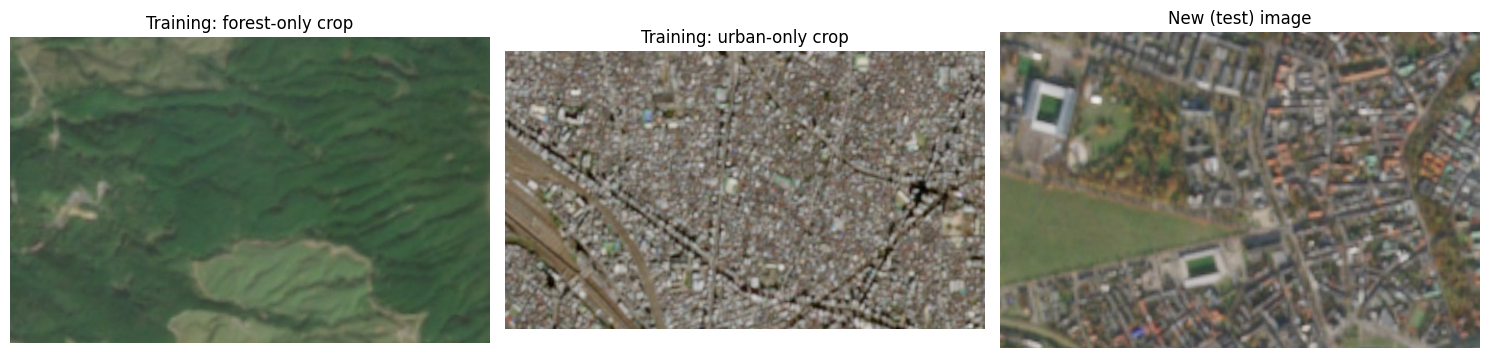

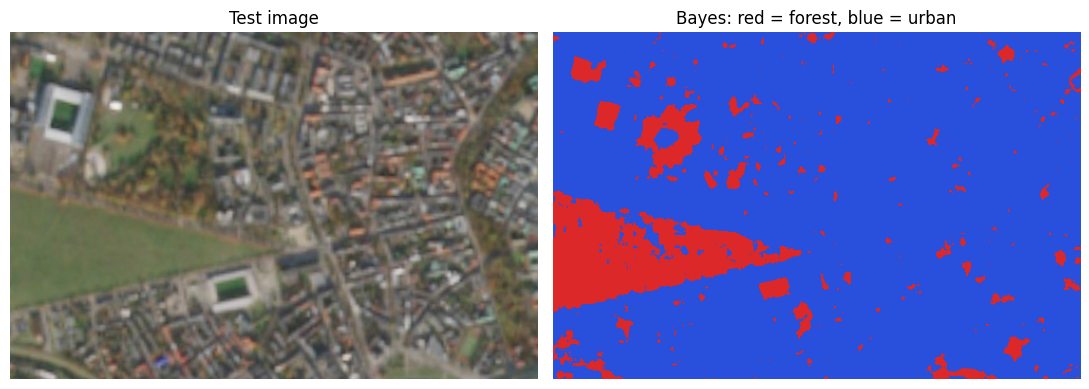

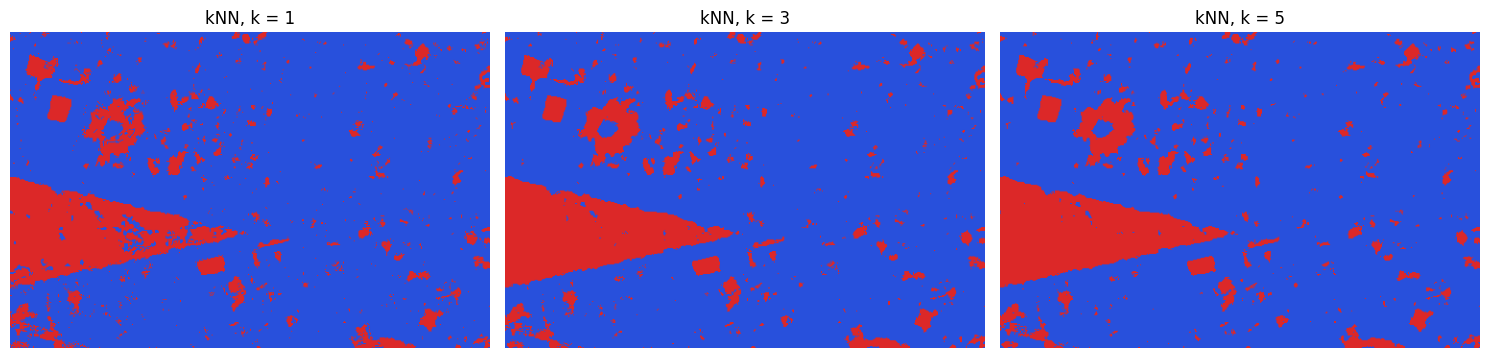

{
 "mu_forest": [
  72.62,
  94.68,
  70.49
 ],
 "mu_urban": [
  122.73,
  116.29,
  105.77
 ],
 "std_forest": [
  18.48,
  14.11,
  11.91
 ],
 "std_urban": [
  23.6,
  24.91,
  26.91
 ],
 "cov_forest": [
  [
   341.4,
   241.4,
   212.3
  ],
  [
   241.4,
   199.2,
   158.4
  ],
  [
   212.3,
   158.4,
   141.8
  ]
 ],
 "cov_urban": [
  [
   556.9,
   572.2,
   600.0
  ],
  [
   572.2,
   620.3,
   653.3
  ],
  [
   600.0,
   653.3,
   724.4
  ]
 ],
 "prior_forest": 0.46854484267823976
}
fraction of pixels that change: {'k1_vs_k3': 0.02474772036474164, 'k3_vs_k5': 0.00931306990881459}


In [18]:
# FIGURES

# Input data
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(forest_img.astype(np.uint8)); ax[0].set_title("Training: forest-only crop")
ax[1].imshow(urban_img.astype(np.uint8));  ax[1].set_title("Training: urban-only crop")
ax[2].imshow(test_img.astype(np.uint8));   ax[2].set_title("New (test) image")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# Bayes result
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(test_img.astype(np.uint8)); ax[0].set_title("Test image")
ax[1].imshow(colorize(pred_bayes));      ax[1].set_title("Bayes: red = forest, blue = urban")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# kNN results
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for j, k in enumerate((1, 3, 5)):
    ax[j].imshow(colorize(knn_preds[k])); ax[j].set_title(f"kNN, k = {k}")
    ax[j].axis("off")
plt.tight_layout(); plt.show()

print(json.dumps(res["params"], indent=1))        # fitted Gaussian parameters
changes = {"k1_vs_k3": float((knn_preds[1] != knn_preds[3]).mean()),
           "k3_vs_k5": float((knn_preds[3] != knn_preds[5]).mean())}
print("fraction of pixels that change:", changes)

Increasing k removes isolated, noise-driven labels: k=1 follows individual training pixels, including atypical ones, while k=3 and k=5 vote among several and give a slightly cleaner map. The effect is small here because most of the image is clearly one class in colour. The overall picture stays the same, and the differences are confined to the ambiguous colours near the class boundary.